In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Connect and Access Git Repository

import os
import sys
import json
from getpass import getpass
from pathlib import Path

GITHUB_USERNAME = "sharaffatima"
REPO_NAME = "bachelor-thesis"



token = getpass("GitHub token: ")


REPO_URL = f"https://{token}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
REPO_DIR = Path("/content") / REPO_NAME


if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull

%cd {REPO_DIR}
sys.path.append(str(REPO_DIR))

print("Repo exists:", REPO_DIR.exists())

GitHub token: ··········
Cloning into '/content/bachelor-thesis'...
remote: Enumerating objects: 394, done.
remote: Counting objects: 100% (130/130), done.
remote: Compressing objects: 100% (110/110), done.
remote: Total 394 (delta 66), reused 46 (delta 19), pack-reused 264 (from 1)
Receiving objects: 100% (394/394), 23.96 MiB | 16.05 MiB/s, done.
Resolving deltas: 100% (183/183), done.
/content/bachelor-thesis
Repo exists: True


In [ ]:
# Imports
import os
import numpy as np
import torch
from torch.utils.data import DataLoader

# global configuration

REPO_DIR = Path("/content/bachelor-thesis")
sys.path.append(str(REPO_DIR))


from utils.dataset import PTBXLAnoFormerDataset
from explainability.attention import AnoFormerExplainability
from utils.seed import set_seed, RANDOM_SEED
from models.anoformer import AnoFormerMainModel
from utils.anomaly_threshold import ChooseThresholdForRecall

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(RANDOM_SEED)
print(f"Active device: {DEVICE}")

Active device: cpu


In [ ]:
# Paths to Directories

DATA_DIR = Path("/content/drive/MyDrive/ECG data")
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"

MODEL_DIR = RESULTS_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

ANOFORMER_MODEL_DIR = MODEL_DIR / "anoformer"
ANOFORMER_MODEL_DIR.mkdir(parents=True, exist_ok=True)


ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_40epochs_larger_capacity_2.pt"

SHAP_RESULTS_DIR = RESULTS_DIR / "shap"
SHAP_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("MODEL_DIR:", ANOFORMER_MODEL_DIR)
print("MODEL_PATH:", ANOFORMER_MODEL_PATH)

MODEL_DIR: /content/drive/MyDrive/ECG data/results/models
MODEL_PATH: /content/drive/MyDrive/ECG data/results/models/anoformer_40epochs_larger_capacity_2.pt


In [ ]:
# Load my preprocessed data

X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")

X_val = np.load(PROCESSED_DIR / "X_val.npy")
y_val = np.load(PROCESSED_DIR / "y_val.npy")

X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(17418, 1000, 12) (17418,)
(2183, 1000, 12) (2183,)
(2198, 1000, 12) (2198,)


In [ ]:
# Training only on normal data

normal_train_mask = y_train == 0

X_train_normal = X_train[normal_train_mask]
y_train_normal = y_train[normal_train_mask]

print("Training on normal ECGs:", X_train_normal.shape)

Training on normal ECGs: (7596, 1000, 12)


In [ ]:
# Datasets

train_dataset = PTBXLAnoFormerDataset(
    X_train_normal,
    y_train_normal,
    normalize=True
)

val_dataset = PTBXLAnoFormerDataset(
    X_val,
    y_val,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

test_dataset = PTBXLAnoFormerDataset(
    X_test,
    y_test,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

In [ ]:
# Dataloaders

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
# Check the shapes

# Expected:
#         Batch X: torch.Size([4, 1000, 12])
#         Batch y: torch.Size([4])

batch_x, batch_y = next(iter(train_loader))

print(batch_x.shape)
print(batch_y.shape)

torch.Size([4, 1000, 12])
torch.Size([4])


In [ ]:
# Create Model

AnoFormer = AnoFormerMainModel(
    NumFeatures=12,
    ModelDimension=64,
    NumHeads=4,
    NumEncoderLayers=2,
    NumDecoderLayers=2,
    DiscriminatorLayers=1,
    ForwardDimension=128,
    DropoutRate=0.1,
    GeneratorLearningRate=1e-4,
    DiscriminatorLearningRate=1e-4,
    MaskingRate=0.15,
    AnomalyThreshold=0.75,
    ReconstructionWeight=10.0,
)

In [ ]:
# Test

batch_x, _ = next(iter(train_loader))
batch_x = batch_x.to(AnoFormer.Device)

with torch.no_grad():
    masked_x, _ = AnoFormer.Masking(batch_x, None)
    reconstruction = AnoFormer.Generator(masked_x)

print("Input:", batch_x.shape)
print("Masked:", masked_x.shape)
print("Reconstruction:", reconstruction.shape)

Input: torch.Size([4, 1000, 12])
Masked: torch.Size([4, 1000, 12])
Reconstruction: torch.Size([4, 1000, 12])


In [ ]:
# Instead of retraining, I can just reload the saved model and use directly for anomaly detection and evaluation etc... no need to run the Training cell

#ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_20epochs.pt"
#ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_40epochs.pt"
#ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_80epochs.pt"
#ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_40epochs_larger_capacity.pt"
ANOFORMER_MODEL_PATH = ANOFORMER_MODEL_DIR / "anoformer_40epochs_larger_capacity_2.pt"

AnoFormer.Load(str(ANOFORMER_MODEL_PATH))

Modell geladen von: /content/drive/MyDrive/ECG data/results/models/anoformer_40epochs_larger_capacity.pt


In [ ]:
AnoFormer.AnomalyLimit = None

In [ ]:
# Training

print("\n── AnoFormer Training starts ─────────────────────────────")

AnoFormer.TrainModel(
    TrainingLoader=train_loader,
    NumEpochs=40,
    PrintInterval=1,
)


── AnoFormer Training starts ─────────────────────────────
Epoche    1/40 | G-Total=5.9380 | G-GAN=1.0571 | G-Rec=0.4881 | D=0.5635
Epoche    2/40 | G-Total=11.2198 | G-GAN=1.7221 | G-Rec=0.9498 | D=0.4224
Epoche    3/40 | G-Total=4.3651 | G-GAN=0.7853 | G-Rec=0.3580 | D=0.6831
Epoche    4/40 | G-Total=11.0383 | G-GAN=1.4788 | G-Rec=0.9559 | D=0.4579
Epoche    5/40 | G-Total=3.9166 | G-GAN=0.7497 | G-Rec=0.3167 | D=0.6889
Epoche    6/40 | G-Total=10.7257 | G-GAN=1.5874 | G-Rec=0.9138 | D=0.4286
Epoche    7/40 | G-Total=3.6806 | G-GAN=0.7300 | G-Rec=0.2951 | D=0.7074
Epoche    8/40 | G-Total=10.6523 | G-GAN=1.6484 | G-Rec=0.9004 | D=0.4290
Epoche    9/40 | G-Total=3.4868 | G-GAN=0.7287 | G-Rec=0.2758 | D=0.7050
Epoche   10/40 | G-Total=10.4928 | G-GAN=1.6536 | G-Rec=0.8839 | D=0.4313
Epoche   11/40 | G-Total=3.3739 | G-GAN=0.7258 | G-Rec=0.2648 | D=0.7066
Epoche   12/40 | G-Total=10.1029 | G-GAN=1.5840 | G-Rec=0.8519 | D=0.4341
Epoche   13/40 | G-Total=3.2430 | G-GAN=0.7189 | G-Rec=0.2

In [ ]:
# Calculate stable anomaly scores for the validation set

ValidationScores = AnoFormer.CalculateScores(
    DataLoaderObject=val_loader,
    NumMaskRuns=5,
    Seed=42,
)

ValidationLabels = np.asarray(y_val).astype(int).reshape(-1)

print("Validation scores shape:", ValidationScores.shape,)
print("Validation labels shape:", ValidationLabels.shape,)
print("Normal validation records:", (ValidationLabels == 0).sum(),)
print("Anomalous validation records:", (ValidationLabels == 1).sum(),)
print("Mean normal score:", ValidationScores[ValidationLabels == 0].mean(),)
print("Mean anomalous score:", ValidationScores[ValidationLabels == 1].mean(),)

Validation scores shape: (2183,)
Validation labels shape: (2183,)
Normal validation records: 955
Anomalous validation records: 1228
Mean normal score: 0.22697824
Mean anomalous score: 0.4549361


In [ ]:
# choose Threshold based on minimum TargetRecall

ThresholdResult = ChooseThresholdForRecall(
    Labels=ValidationLabels,
    Scores=ValidationScores,
    TargetRecall=0.80,
)

ChosenThreshold = ThresholdResult["Threshold"]

print("Chosen threshold:", ChosenThreshold)
print("Validation precision:", ThresholdResult["Precision"])
print("Validation recall:", ThresholdResult["Recall"])

Chosen threshold: 0.17710630595684052
Validation precision: 0.5960024227740763
Validation recall: 0.8013029315960912


In [ ]:
# Anomaly detection

print("\n── AnoFormer Anomaly Detection ───────────────────────────")

TestScores, TestPredictions = AnoFormer.DetectAnomalies(
    TestLoader=test_loader,
    Threshold=ChosenThreshold,
    NumMaskRuns=5,
    Seed=42,
)

TestLabels = np.asarray(y_test).astype(int).reshape(-1)

print("Test scores shape:", TestScores.shape)
print("Test predictions shape:", TestPredictions.shape)
print("Detected anomalous ECG records:", TestPredictions.sum())
print("Validation-derived threshold:", AnoFormer.AnomalyLimit)


── AnoFormer Anomaly Detection ───────────────────────────
Test scores shape: (2198,)
Test predictions shape: (2198,)
Detected anomalous ECG records: 1663
Validation-derived threshold: 0.17710630595684052


In [ ]:
# Evaluation

print("\n── AnoFormer Evaluation ───────────────────────────")

TestLabels = np.asarray(y_test).astype(int).reshape(-1)

Metrics = AnoFormer.Evaluate(
    TrueLabels=TestLabels,
    Scores=TestScores,
    PredictedLabels=TestPredictions,
)


── AnoFormer Evaluation ───────────────────────────
  Accuracy            : 0.5851
  Precision           : 0.5971
  Recall              : 0.804
  F1Score             : 0.6853
  FalseNegativeRate   : 0.196
  Threshold           : 0.177106
  TruePositive        : 993
  TrueNegative        : 293
  FalsePositive       : 670
  FalseNegative       : 242

Confusion matrix:
 [[293 670]
 [242 993]]
ROC-AUC: 0.6463
PR-AUC: 0.7303


In [ ]:
# Save the Model after training

print("\n── Saving AnoFormer ──────────────────────────────────────")

AnoFormer.Save(str(ANOFORMER_MODEL_PATH))


── Saving AnoFormer ──────────────────────────────────────
Modell gespeichert unter: /content/drive/MyDrive/ECG data/results/models/anoformer_40epochs_larger_capacity_2.pt


In [ ]:
# Correctly predicted normal samples
correct_normal_indices = np.where(
    (y_test == 0) & (TestPredictions == 0)
)[0]

# Correctly predicted anomalous samples
correct_anomaly_indices = np.where(
    (y_test == 1) & (TestPredictions == 1)
)[0]

# Pick the most confident normal: lowest anomaly score
NormalIndex = correct_normal_indices[
    np.argmin(TestScores[correct_normal_indices])
]

# Pick the most confident anomaly: highest anomaly score
AnomalousIndex = correct_anomaly_indices[
    np.argmax(TestScores[correct_anomaly_indices])
]

print("Selected normal index:", NormalIndex)
print("Normal score:", TestScores[NormalIndex])
print("Selected anomalous index:", AnomalousIndex)
print("Anomalous score:", TestScores[AnomalousIndex])

Selected normal index: 2044
Normal score: 0.036472023
Selected anomalous index: 1801
Anomalous score: 5.664149


In [ ]:
# Save the chosen samples to reuse in the SHAP explaianbility

selected_samples = {
    "normal_index": int(NormalIndex),
    "anomalous_index": int(AnomalousIndex),
    "selection_method": {
        "normal": "Correctly predicted normal with lowest anomaly score",
        "anomalous": "Correctly predicted anomaly with highest anomaly score",
    },
    "anoformer": {
        "normal_score": float(TestScores[NormalIndex]),
        "anomalous_score": float(TestScores[AnomalousIndex]),
        "normal_prediction": int(TestPredictions[NormalIndex]),
        "anomalous_prediction": int(TestPredictions[AnomalousIndex]),
    },
}

samples_path = (
    SHAP_RESULTS_DIR
    / "anoformer_selected_sample_indices.json"
)

with open(samples_path, "w") as file:
    json.dump(selected_samples, file, indent=4)

print("Saved selected samples to:", samples_path)

Saved selected samples to: /content/drive/MyDrive/ECG data/results/shap/anoformer_selected_sample_indices.json


Normal index: 2044 Label: 0
Anomalous index: 1801 Label: 1


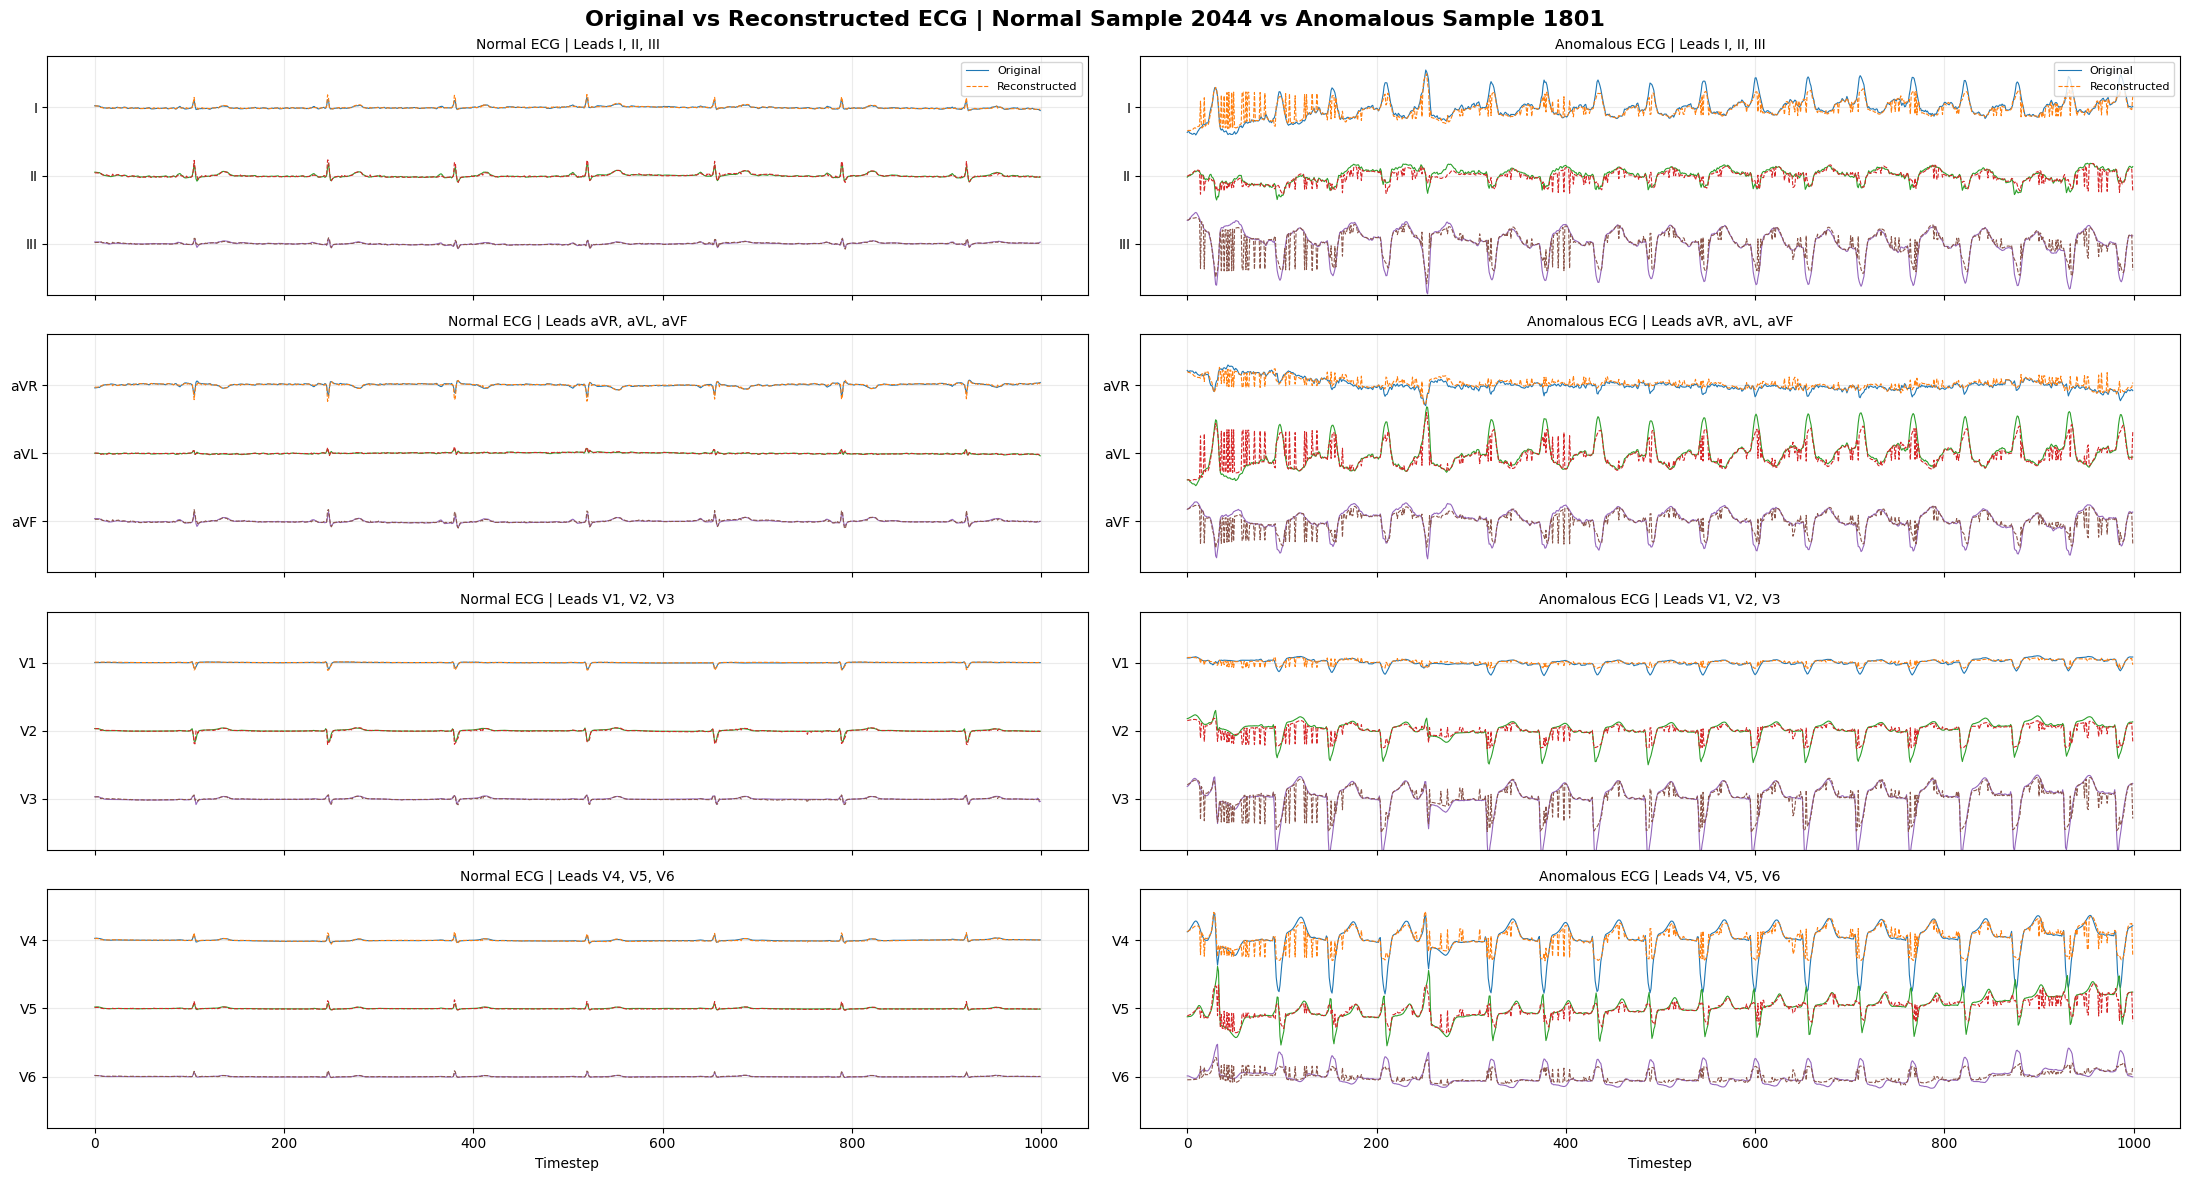

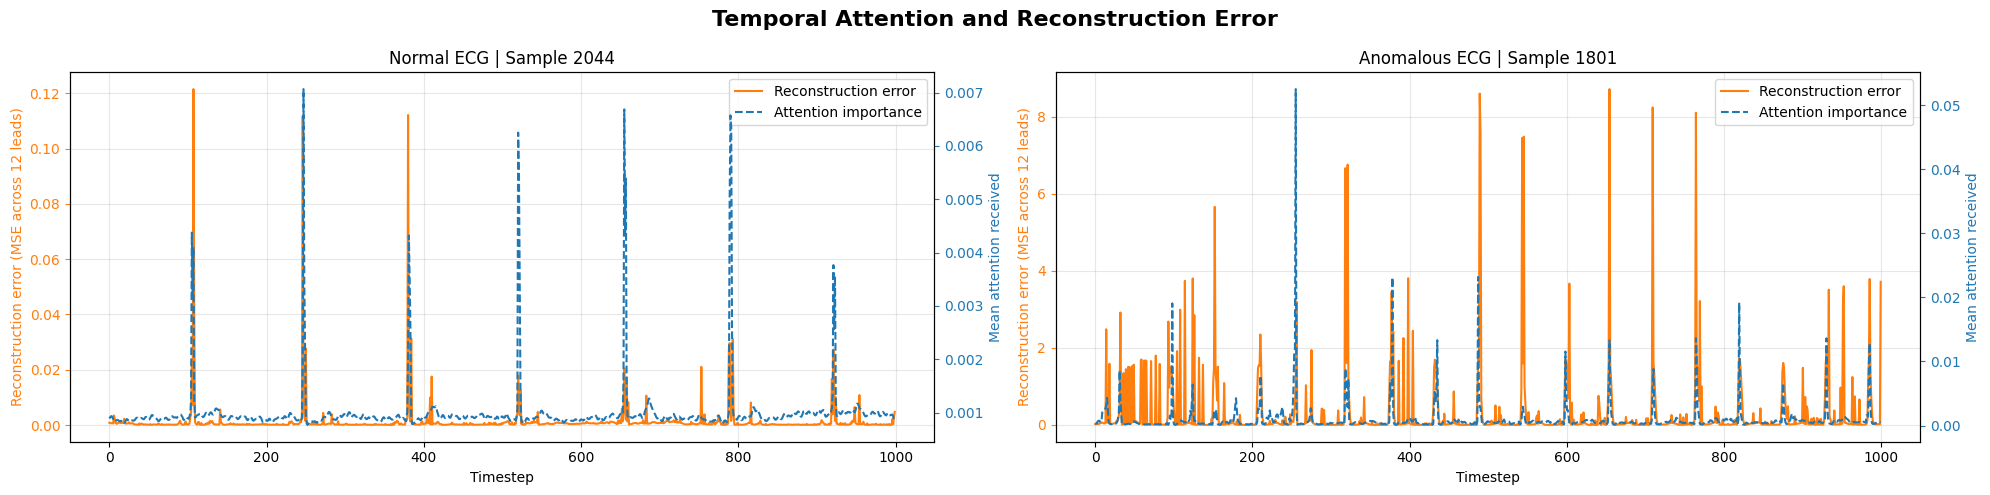

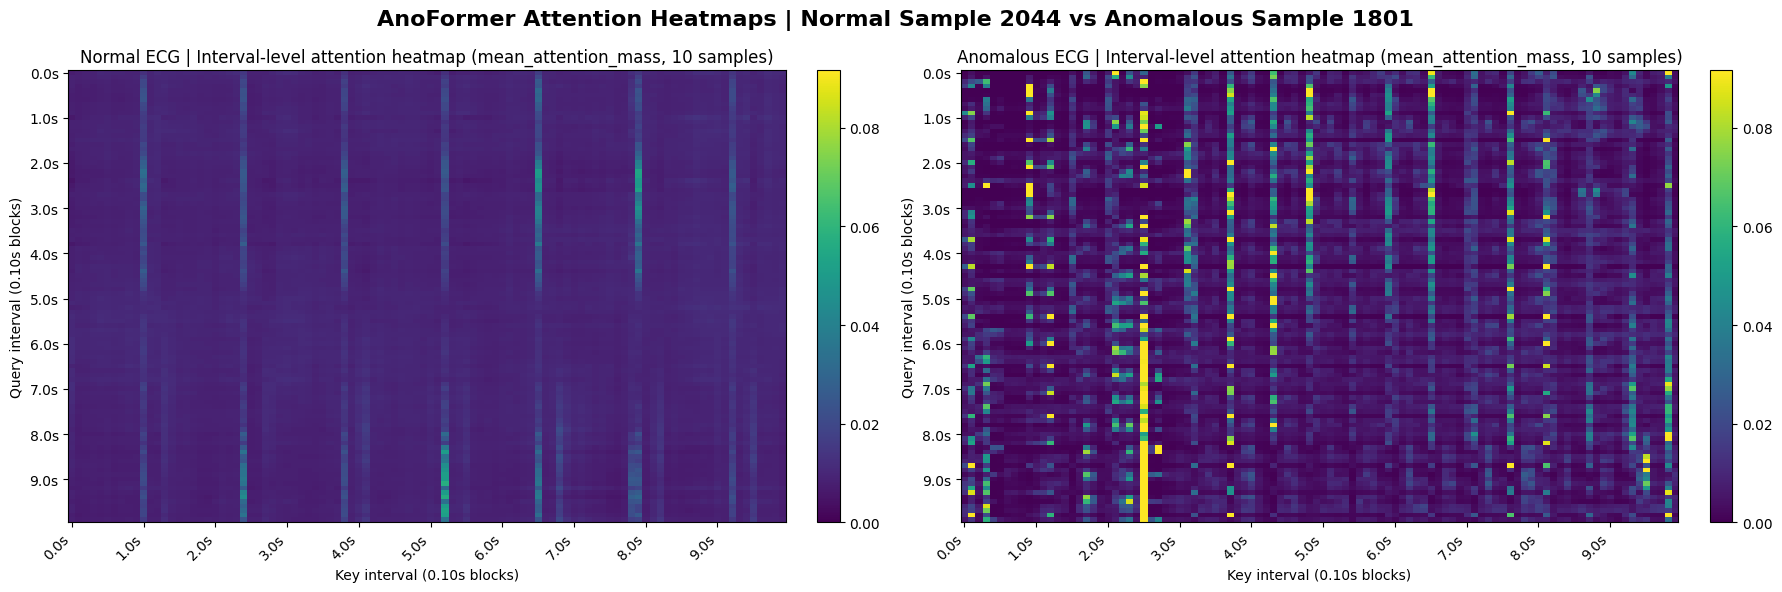

In [ ]:
# AnoFormer Attention-based Explainability


print("\n── AnoFormer Attention-based Explainability ─────────────────────")

Explainer = AnoFormerExplainability(AnoFormer)


NormalECG, NormalLabel = test_dataset[NormalIndex]
AnomalousECG, AnomalousLabel = test_dataset[AnomalousIndex]

NormalECG = NormalECG.unsqueeze(0).to(AnoFormer.Device)
AnomalousECG = AnomalousECG.unsqueeze(0).to(AnoFormer.Device)

print("Normal index:", NormalIndex, "Label:", NormalLabel.item())
print("Anomalous index:", AnomalousIndex, "Label:", AnomalousLabel.item())

Explainer.CompareNormalAndAnomalousAttention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    BlockIndex=0,
    HeadIndex=None,
    Percentile=99.0,
    UseIntervalHeatmap=True,
    BlockSize=10,
    Aggregation="mean_attention_mass",
    SamplingRate=100,
)

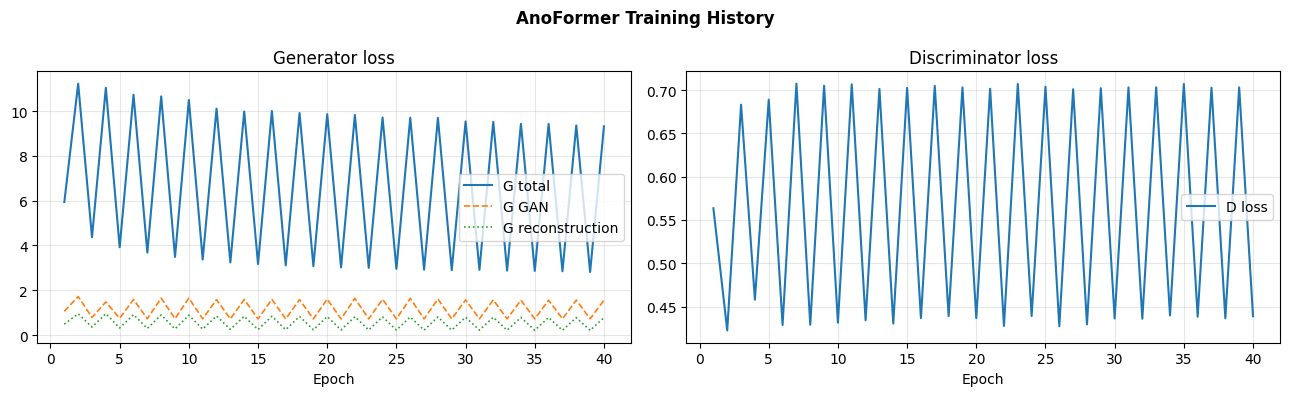

In [ ]:
# Show training loss

Explainer.ShowTrainingHistory()